In [29]:
!python -V

Python 3.13.14


In [30]:
# %conda create -n mlops-venv
# %conda activate mlops-venv
%pip install -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [31]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [32]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import (
    LinearRegression, 
    Lasso, 
    Ridge
)
from sklearn.metrics import root_mean_squared_error
from pathlib import Path

In [33]:
import mlflow

mlflow.set_tracking_uri("sqlite:///../db/mlflow.db")
mlflow.set_experiment("nyc-taxi-experiment")

<Experiment: artifact_location='file:c:/Users/okech/code/mlops-hero/notebooks/mlruns/1', creation_time=1793433080522, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793433080522, lifecycle_stage='active', name='nyc-taxi-experiment', tags={}, trace_location=None, workspace='default'>

In [34]:
def read_dataframe(filename: str | Path): # ../data/green_tripdata_2026-07.parquet
    df = pd.read_parquet(filename)

    # Calculate the trip durations using pickup and dropoff times and convert to minutes
    df['duration'] = df.lpep_dropoff_datetime - df.lpep_pickup_datetime
    df.duration = df.duration.apply(lambda td: td.total_seconds() / 60)

    # Filter trips that lasted between a minute and an hour
    df = df[(df.duration >= 1) & (df.duration <= 60)]

    # Cast categorical features to strings
    categorical = ['PULocationID', 'DOLocationID']

    df[categorical] = df[categorical].astype(str)
    return df

In [35]:
# Load the training and validation datasets (08-2026 and 09-2026, respectively) into dataframes
train_data = Path('../data/green_tripdata_2026-07.parquet')
valid_data = Path('../data/green_tripdata_2026-08.parquet')
df_train = read_dataframe(train_data)
df_val = read_dataframe(valid_data)
df_train.shape, df_val.shape

((38779, 23), (38435, 23))

In [36]:
# Extract categorical and numerical features from the datasets
df_train['PU_DO'] = df_train['PULocationID'] + '_' + df_train['DOLocationID'] # Add a new feature column that pairs the pickup and drop off locations to improve the model's performance
df_val['PU_DO'] = df_val['PULocationID'] + '_' + df_val['DOLocationID']
categorical = ['PU_DO'] # PULocationID, DOLocationID
numerical =  ['trip_distance']

# Transform the features into vectors
dv = DictVectorizer() # Create a dictionary vectorizer object

train_dicts = df_train[categorical + numerical].to_dict(orient='records')
val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts) # Learn the list of feature-name mappings from the training data and transform to an array
X_val = dv.transform(val_dicts) # Transform the feature-value mappings to an array, dropping unknown mappings learned during the fit_transform
X_train.shape, X_val.shape # Check that the training and validation data have equal shape



((38779, 5799), (38435, 5799))

In [37]:
dv.feature_names_  # Features used by the dict vectorizer

['PU_DO=100_151',
 'PU_DO=100_169',
 'PU_DO=100_235',
 'PU_DO=100_42',
 'PU_DO=100_74',
 'PU_DO=100_78',
 'PU_DO=101_101',
 'PU_DO=101_129',
 'PU_DO=101_131',
 'PU_DO=101_16',
 'PU_DO=101_19',
 'PU_DO=101_191',
 'PU_DO=101_203',
 'PU_DO=101_254',
 'PU_DO=101_258',
 'PU_DO=101_98',
 'PU_DO=102_122',
 'PU_DO=102_124',
 'PU_DO=102_132',
 'PU_DO=102_135',
 'PU_DO=102_196',
 'PU_DO=102_222',
 'PU_DO=102_63',
 'PU_DO=102_82',
 'PU_DO=102_83',
 'PU_DO=102_95',
 'PU_DO=106_256',
 'PU_DO=106_37',
 'PU_DO=106_39',
 'PU_DO=106_40',
 'PU_DO=106_55',
 'PU_DO=106_61',
 'PU_DO=106_71',
 'PU_DO=107_143',
 'PU_DO=107_202',
 'PU_DO=107_237',
 'PU_DO=107_48',
 'PU_DO=107_60',
 'PU_DO=107_88',
 'PU_DO=107_89',
 'PU_DO=108_14',
 'PU_DO=108_149',
 'PU_DO=108_177',
 'PU_DO=108_72',
 'PU_DO=108_80',
 'PU_DO=10_102',
 'PU_DO=10_130',
 'PU_DO=10_131',
 'PU_DO=10_134',
 'PU_DO=10_170',
 'PU_DO=10_188',
 'PU_DO=10_197',
 'PU_DO=10_215',
 'PU_DO=10_216',
 'PU_DO=10_48',
 'PU_DO=10_56',
 'PU_DO=10_61',
 'PU_DO=10_7

In [38]:
target = 'duration'
y_train = df_train[target].values 
y_val = df_val[target].values
len(y_train), len(y_val)

(38779, 38435)

In [39]:
# Experiment tracking with MLflow
with mlflow.start_run():
    mlflow.set_tag("model", "linear_regression")
    mlflow.log_param("train-data-path", train_data)
    mlflow.log_param("valid-data-path", valid_data)

    # Use the linear regression model to fit the training dataset
    lin_reg = LinearRegression()
    print(X_train.shape, X_val.shape, len(y_train))
    lin_reg.fit(X_train, y_train)

    # Predict the target values using the fitted model and the validation dataset
    y_pred_lin_reg = lin_reg.predict(X_val)

    # Compute the rms error between the predicted and actual values in the validation dataset
    rmse = root_mean_squared_error(y_val, y_pred_lin_reg) 
    mlflow.log_metric("rmse", rmse)

(38779, 5799) (38435, 5799) 38779


In [ ]:
# Lasso Model
with mlflow.start_run():
    mlflow.set_tag("model", "lasso")

    alpha = 0.0001
    mlflow.log_param("alpha", alpha)
    mlflow.log_param("train-data-path", train_data)
    mlflow.log_param("valid-data-path", valid_data)
    
    lasso = Lasso(alpha=alpha)
    print(X_train.dtype, y_train.dtype) #int64
    # Convert the sparse matrix indices from int64 to int32, the accepted dtype for Lasso
    X_train.indices = X_train.indices.astype('int32')
    X_train.indptr = X_train.indptr.astype('int32')
    X_val.indices = X_val.indices.astype('int32')
    X_val.indptr = X_val.indptr.astype('int32')
    lasso.fit(X_train, y_train)
    y_pred_lasso = lasso.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred_lasso)
    mlflow.log_metric("rmse", rmse)


float64 float64
None


In [41]:
# Ridge Model

with mlflow.start_run():
    mlflow.set_tag("model", "ridge")

    alpha=0.001
    mlflow.log_param("alpha", alpha)
    mlflow.log_param("train-data-path", train_data)
    mlflow.log_param("valid_data", valid_data)
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train, y_train)
    y_pred_ridge = lin_reg.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred_ridge)
    mlflow.log_metric("rmse", rmse)

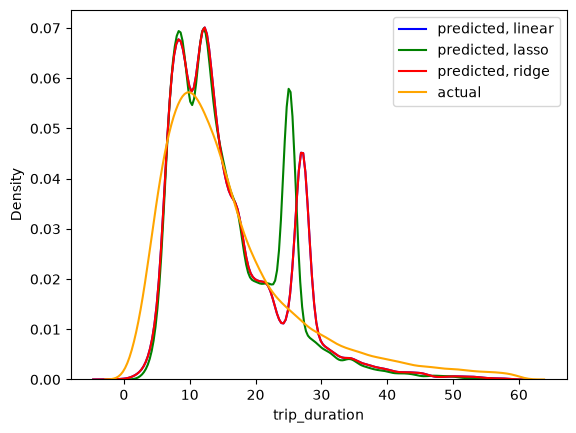

In [42]:
# Plot the distributions of the predicted and actual trip durations
col_name = 'trip_duration'
y_pred_lin_reg_df = pd.DataFrame(y_pred_lin_reg, columns=[col_name])
y_pred_lasso_df = pd.DataFrame(y_pred_lasso, columns=[col_name])
y_pred_ridge_df = pd.DataFrame(y_pred_ridge, columns=[col_name])
y_train_df = pd.DataFrame(y_train, columns=[col_name])
sns.kdeplot(data=y_pred_lin_reg_df, x=col_name, label='predicted, linear', color='blue')
sns.kdeplot(data=y_pred_lasso_df, x=col_name, label='predicted, lasso', color='green')
sns.kdeplot(data=y_pred_ridge_df, x=col_name, label='predicted, ridge', color='red')
sns.kdeplot(data=y_train_df, x=col_name, label='actual', color='orange')
plt.legend()
plt.show()


In [43]:

import pickle
from pathlib import Path

# Writes a model's artifact to file using pickle
def write_model_to_file(artifact: dict, path: str):
    file = Path(path)
    file.parent.mkdir(parents=True, exist_ok=True)
   
    with open(file, 'wb') as f:
        pickle.dump(artifact, f)



# Load a model from a pickled file
def read_model_from_file(path: str):
    file = Path(path)

    if not file.exists():
        raise FileNotFoundError(f"No model file found at: {file.absolute()}")

    with open(file, 'rb') as f:
        model = pickle.load(f)

    return model



In [44]:
# Save the models

linear_reg_artifacts, linear_reg_path = {'vectorizer': dv, 'model': lin_reg}, '../models/linear.pkl' 


lasso_artifacts, lasso_path = {'vectorizer': dv, 'model': lasso}, '../models/lasso.pkl'

ridge_artifacts, ridge_path = {'vectorizer': dv, 'model': ridge}, '../models/ridge.pkl'

for artifact, filepath in zip([linear_reg_artifacts, lasso_artifacts, ridge_artifacts], [linear_reg_path, lasso_path, ridge_path]):
    write_model_to_file(artifact, filepath)
